# Sistema de agrupación de casas — K-Means + clasificación supervisada

Usamos el dataset *California Housing* (censo de 1990) para agrupar las casas según su región (`Latitude`, `Longitude`) y su ingreso medio (`MedInc`) con un K-Means, y después entrenamos un modelo supervisado que aprenda a predecir esos grupos.

In [1]:
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

## Paso 1: Carga del conjunto de datos

Solo nos interesan las columnas `Latitude`, `Longitude` y `MedInc`.

In [2]:
total_data = pd.read_csv("../data/raw/housing.csv")
# Alternativa: pd.read_csv("https://breathecode.herokuapp.com/asset/internal-link?id=809&path=housing.csv")
total_data = total_data[["Latitude", "Longitude", "MedInc"]]
total_data.head()

,Latitude,Longitude,MedInc
0,37.88,-122.23,8.3252
1,37.86,-122.22,8.3014
2,37.85,-122.24,7.2574
3,37.85,-122.25,5.6431
4,37.85,-122.25,3.8462


In [3]:
print(total_data.shape)
print("Nulos:", total_data.isna().sum().sum())
total_data.describe()

(20640, 3)
Nulos: 0


,Latitude,Longitude,MedInc
count,20640.000000,20640.000000,20640.000000
mean,35.631861,-119.569704,3.870671
std,2.135952,2.003532,1.899822
min,32.540000,-124.350000,0.499900
25%,33.930000,-121.800000,2.563400
50%,34.260000,-118.490000,3.534800
75%,37.710000,-118.010000,4.743250
max,41.950000,-114.310000,15.000100


No hay valores nulos. Las tres variables tienen escalas comparables (latitud ≈ 32–42, longitud ≈ −124 a −114, ingreso ≈ 0.5–15, en decenas de miles de dólares), así que podemos usarlas directamente en el K-Means sin escalar.

Dividimos en `train` y `test`: el K-Means se ajusta con `train` y luego se usa para predecir el cluster de los puntos nuevos de `test`.

In [4]:
X_train, X_test = train_test_split(total_data, test_size=0.2, random_state=RANDOM_STATE)
X_train.shape, X_test.shape

((16512, 3), (4128, 3))

## Paso 2: Construye un K-Means con 6 clusters

In [5]:
kmeans = KMeans(n_clusters=6, n_init="auto", random_state=RANDOM_STATE)
kmeans.fit(X_train)

y_train = list(kmeans.labels_)
X_train = X_train.copy()
X_train["cluster"] = y_train
X_train.head()

,Latitude,Longitude,MedInc,cluster
14196,32.71,-117.03,3.2596,3
8267,33.77,-118.16,3.8125,1
17445,34.66,-120.48,4.1563,1
14265,32.69,-117.11,1.9425,3
2271,36.78,-119.80,3.5542,5


Las etiquetas que devuelve `KMeans` son enteros (0–5). Aunque sean números, **no tienen orden ni magnitud**: son categorías. Por eso, para graficar, la convertimos a tipo `category`, y así `seaborn` usa una paleta categórica en lugar de un degradado.

In [6]:
X_train["cluster"] = X_train["cluster"].astype("category")

centers = pd.DataFrame(kmeans.cluster_centers_, columns=["Latitude", "Longitude", "MedInc"]).round(2)
centers["n_casas"] = X_train["cluster"].value_counts().sort_index().values
centers

,Latitude,Longitude,MedInc,n_casas
0,37.69,-121.92,5.38,2455
1,33.89,-118.00,4.35,3807
2,33.85,-118.04,6.94,1280
3,34.04,-118.02,2.43,4368
4,35.88,-120.28,11.75,246
5,38.14,-121.62,2.74,4356


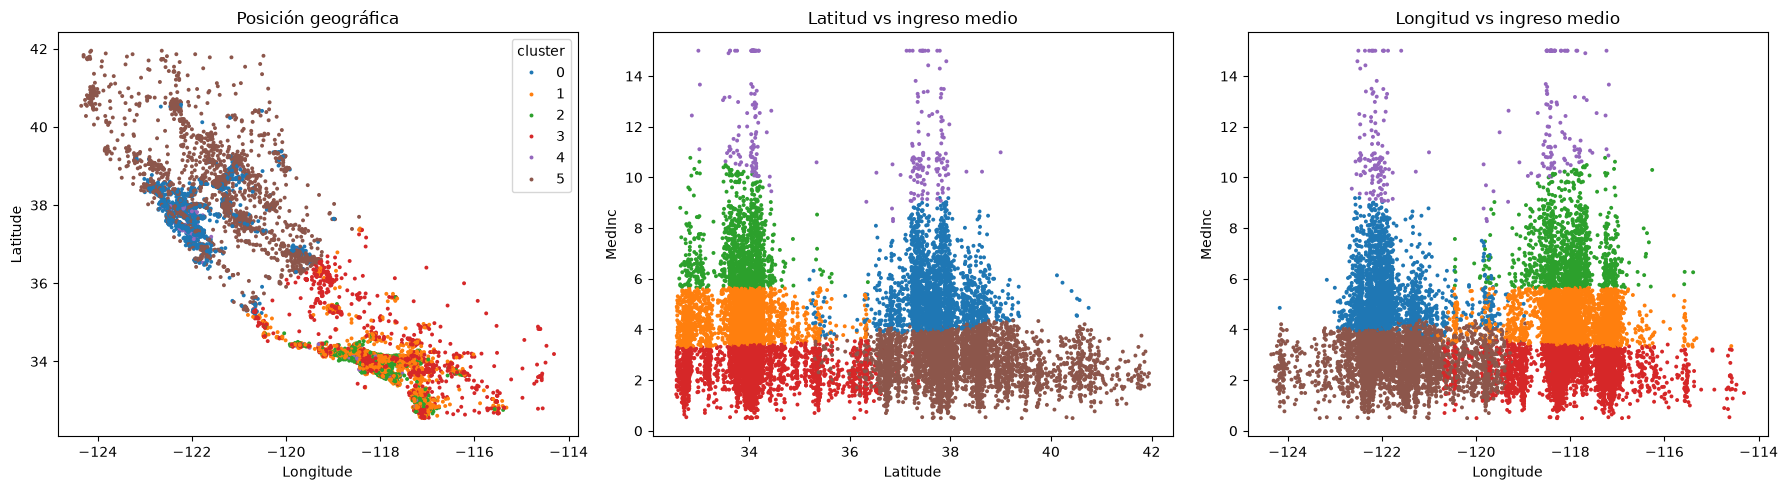

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette = sns.color_palette("tab10", 6)

sns.scatterplot(ax=axes[0], data=X_train, x="Longitude", y="Latitude", hue="cluster", palette=palette, s=8, linewidth=0)
sns.scatterplot(ax=axes[1], data=X_train, x="Latitude", y="MedInc", hue="cluster", palette=palette, s=8, linewidth=0, legend=False)
sns.scatterplot(ax=axes[2], data=X_train, x="Longitude", y="MedInc", hue="cluster", palette=palette, s=8, linewidth=0, legend=False)
axes[0].set_title("Posición geográfica")
axes[1].set_title("Latitud vs ingreso medio")
axes[2].set_title("Longitud vs ingreso medio")
plt.tight_layout()
plt.show()

**Qué vemos:**

- El K-Means separa primero por **región**: un bloque al **norte** (área de la Bahía de San Francisco / Sacramento, latitud ≈ 37–38) y otro al **sur** (Los Ángeles / Orange County / San Diego, latitud ≈ 34). En el mapa (izquierda) se ve casi la silueta de California, partida en dos alrededor de la latitud 35–36.
- Dentro de cada región, divide por **nivel de ingreso**, lo que se ve como bandas horizontales en los gráficos de `MedInc`:
  - Norte: un cluster de ingreso bajo (≈ 2.7) y otro de ingreso medio-alto (≈ 5.4).
  - Sur: tres niveles — bajo (≈ 2.4), medio (≈ 4.3) y alto (≈ 6.9).
- Hay un cluster pequeño (~250 casas) de **ingreso muy alto** (≈ 11.7, incluye los valores topados a 15) que aparece tanto en la Bahía de San Francisco como en Los Ángeles: en él pesa más el ingreso que la ubicación, y su centro geográfico queda "en medio" de las dos regiones.
- La región sur tiene más clusters porque concentra más casas, y el K-Means minimiza la inercia dedicando más centros a las zonas densas.

## Paso 3: Predice con el conjunto de test

In [8]:
y_test = list(kmeans.predict(X_test))
X_test = X_test.copy()
X_test["cluster"] = pd.Categorical(y_test, categories=X_train["cluster"].cat.categories)
X_test.head()

,Latitude,Longitude,MedInc,cluster
20046,36.06,-119.01,1.6812,3
3024,35.14,-119.46,2.5313,3
15663,37.80,-122.44,3.4801,5
20484,34.28,-118.72,5.7376,2
9814,36.62,-121.93,3.7250,5


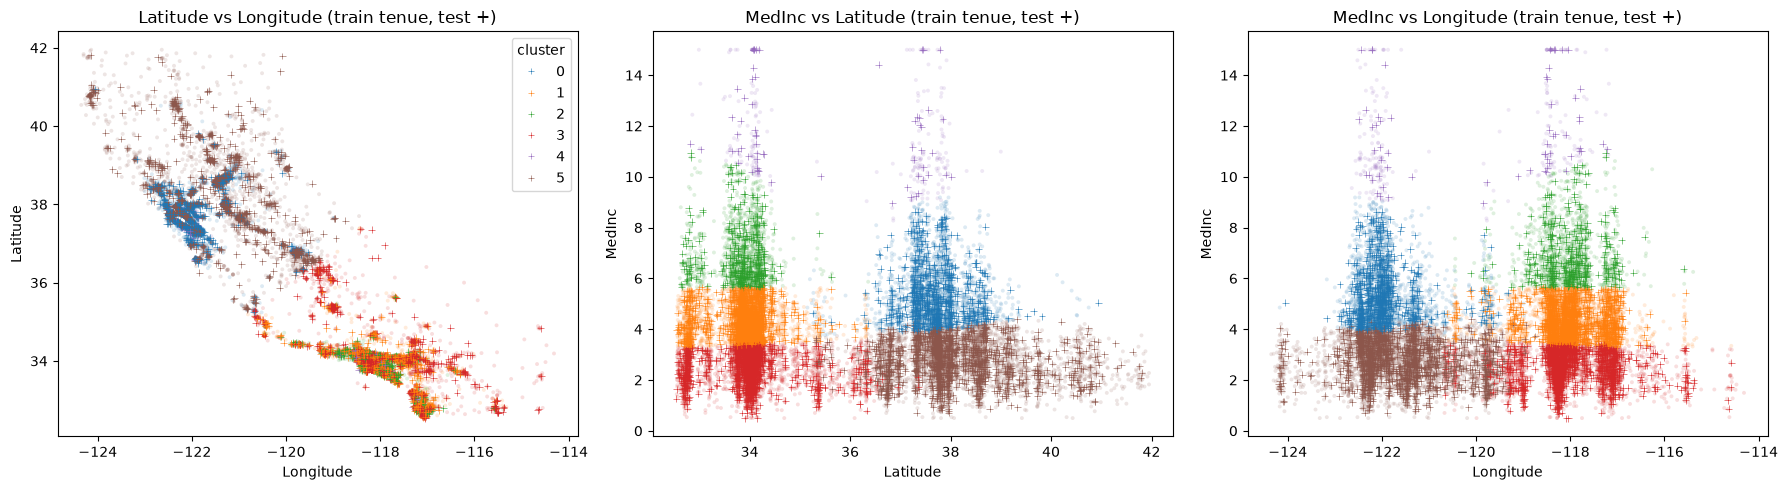

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [("Longitude", "Latitude"), ("Latitude", "MedInc"), ("Longitude", "MedInc")]

for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(ax=ax, data=X_train, x=x, y=y, hue="cluster", palette=palette, s=8, linewidth=0, alpha=0.15, legend=False)
    sns.scatterplot(ax=ax, data=X_test, x=x, y=y, hue="cluster", palette=palette, s=25, marker="+", legend=ax is axes[0])
    ax.set_title(f"{y} vs {x} (train tenue, test +)")
plt.tight_layout()
plt.show()

Los puntos de test (`+`) caen sobre las mismas regiones de color que los de entrenamiento y cada uno recibe el color de la nube en la que cae: la asignación es coherente. Es lo esperable, ya que el K-Means asigna cada punto nuevo al centroide más cercano, de modo que las fronteras entre clusters son las mismas para train y test. La predicción es **satisfactoria**.

## Paso 4: Entrena un modelo de clasificación supervisada

Ahora usamos las etiquetas del K-Means como variable objetivo. Las fronteras de K-Means son regiones de Voronoi (hiperplanos entre centroides), así que:

- una **regresión logística** (modelo lineal) debería aprenderlas bien;
- un **árbol de decisión** o un **Random Forest** también, aproximando las fronteras oblicuas con cortes escalonados.

Comparamos los tres.

In [10]:
X_train_sup = X_train.drop(columns="cluster")
X_test_sup = X_test.drop(columns="cluster")

candidates = {
    "LogisticRegression": LogisticRegression(max_iter=10000),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE),
}

results = {}
for name, model in candidates.items():
    model.fit(X_train_sup, y_train)
    results[name] = {
        "train_accuracy": accuracy_score(y_train, model.predict(X_train_sup)),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test_sup)),
    }
pd.DataFrame(results).T.sort_values("test_accuracy", ascending=False)

,train_accuracy,test_accuracy
RandomForest,1.000000,0.995640
DecisionTree,1.000000,0.994186
LogisticRegression,0.985586,0.986434


Los tres superan el 98 % de accuracy. Nos quedamos con el **Random Forest**, que es el que mejor generaliza en test. Vemos sus métricas en detalle:

In [11]:
model = candidates["RandomForest"]
y_pred = model.predict(X_test_sup)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.995     0.995     0.995       561
           1      0.995     0.999     0.997       983
           2      0.993     0.997     0.995       299
           3      0.997     0.996     0.997      1111
           4      0.984     0.968     0.976        62
           5      0.996     0.994     0.995      1112

    accuracy                          0.996      4128
   macro avg      0.993     0.991     0.992      4128
weighted avg      0.996     0.996     0.996      4128



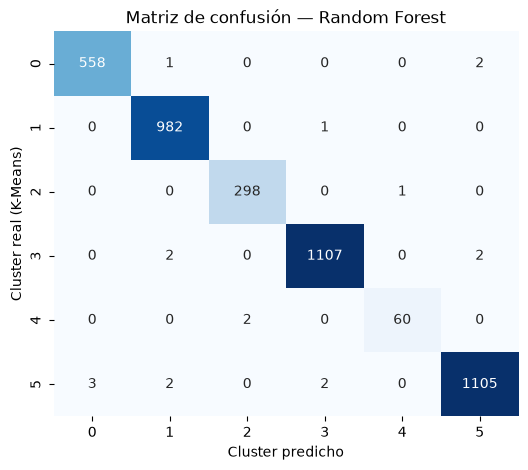

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Cluster predicho")
plt.ylabel("Cluster real (K-Means)")
plt.title("Matriz de confusión — Random Forest")
plt.show()

**Qué vemos:**

- El modelo supervisado reproduce casi a la perfección la agrupación del K-Means (≈ 99.5 % de accuracy en test), con precisión y recall altos en todas las clases.
- Los pocos errores se concentran en puntos situados **justo en la frontera** entre dos clusters vecinos (p. ej. dos niveles de ingreso de la misma región), donde una pequeña diferencia en `MedInc` cambia el centroide más cercano.
- El cluster de ingreso muy alto tiene pocas muestras, por lo que sus métricas son algo más sensibles a cada error individual.
- Era esperable un resultado tan alto: la etiqueta es una función determinista de las propias variables de entrada. La utilidad del flujo es que, con datos sin etiquetar, el modelo no supervisado crea las etiquetas y el supervisado las convierte en un clasificador reutilizable.

## Paso 5: Guarda los modelos

In [13]:
with open("../models/kmeans_6_clusters_42.sav", "wb") as f:
    pickle.dump(kmeans, f)

with open("../models/random_forest_classifier_42.sav", "wb") as f:
    pickle.dump(model, f)